# Notebook 05 – Cải tiến mô hình, tối ưu siêu tham số và đánh giá cuối trên tập kiểm tra
Mọi lựa chọn (đặc trưng, thuật toán, siêu tham số) chỉ dựa trên **CV 5-fold trên tập huấn luyện** với cùng fold như notebook 03–04.
Tập kiểm tra 80 mẫu chỉ được dùng **một lần** ở mục 6, sau khi đã chốt mô hình cuối. Chạy notebook từ thư mục `notebooks/`.

In [1]:
import sys; sys.path.insert(0, "../src")
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

from data import NUM, CAT, TARGET, SEED, split
from preprocess import build_preprocessor
from evaluate import cv_folds, cv_score, fmt, rmse
from features import add_features, LOG, RATIO, DIESEL

warnings.filterwarnings("ignore", category=RuntimeWarning)
FIG, REP = Path("../reports/figures"), Path("../reports")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

train, test = split()
y = train[TARGET]
folds = cv_folds(train)
POLY = ["weight", "horsepower", "acceleration", "model_year"]

def make(model, num, degree=1, log_y=False):
    """Pipeline: thêm đặc trưng -> tiền xử lý (điền thiếu, đa thức, chuẩn hóa, one-hot) -> mô hình; tùy chọn học trên log(MPG)."""
    pipe = make_pipeline(FunctionTransformer(add_features), build_preprocessor(num, CAT, degree), model)
    return TransformedTargetRegressor(pipe, func=np.log if log_y else None, inverse_func=np.exp if log_y else None)

DEG = "regressor__columntransformer__num__polynomialfeatures__degree"
RIDGE_GRID = {DEG: [1, 2, 3], "regressor__ridge__alpha": np.logspace(-3, 3, 13)}

def tune(model, grid, X=train):
    """GridSearchCV trên cùng 5 fold; trả về mô hình tốt nhất (chưa khớp) và bảng kết quả đủ chỉ số."""
    gs = GridSearchCV(model, grid, cv=folds, scoring="neg_root_mean_squared_error").fit(X, y)
    return clone(gs.best_estimator_), gs

## 1. Hạn chế của mô hình ban đầu (bằng chứng từ notebook 03–04)
| Hạn chế | Bằng chứng |
|---|---|
| H1. Đa thức không điều chuẩn quá khớp rất nhanh | Bậc 3 RMSE CV 3,62 ± 1,86, bậc 10 là 28,43 trong khi RMSE huấn luyện chỉ 1,76; variance bootstrap tăng từ 0,66 (bậc 2) lên 3342 (bậc 10) |
| H2. Sai số lớn ở xe đời mới, xe nhẹ, xe diesel | RMSE Ridge nhóm 1980–82 là 4,17 so với 2,08–2,63 các nhóm khác; nhóm < 2200 lb là 3,62 so với 1,64 ở nhóm ≥ 3500 lb; 2 trong 10 mẫu sai nhất là xe diesel (sai 7,7–11,2 MPG) |
| H3. Phương sai sai số không đều | Phần dư của tuyến tính lớn và dương ở hai đầu (MPG dự đoán < 15 và > 30), tức quan hệ cong và độ phân tán tăng theo MPG |
| H4. Mô hình 4 đặc trưng bỏ qua thông tin | `displacement` có hệ số chuẩn hóa 2,90 và permutation importance 1,92 trong mô hình tuyến tính 7 đặc trưng |

| Giải pháp | Gắn với hạn chế | Cơ sở |
|---|---|---|
| G1. Ridge + chọn bậc và α bằng GridSearchCV | H1 | Phạt L2 giảm variance (mục 1.3.1) |
| G2. Học trên log(MPG) | H2, H3 | Tương quan log–log mạnh hơn tuyến tính (−0,874 so với −0,832), log làm phương sai sai số đều hơn |
| G3. Thêm `displacement`, `cylinders`, log của khối lượng/công suất/dung tích, công suất trên tấn | H2, H4 | Quan hệ dạng lũy thừa; tỷ lệ công suất/khối lượng là thông số đặc trưng hiệu năng |
| G4. Cờ `diesel` (lấy từ tên xe) | H2 | Động cơ diesel tiết kiệm hơn xe xăng cùng cỡ; là thông số kỹ thuật thật, không dùng thông tin MPG |
| G5. Thuật toán mới: Random Forest, Gradient Boosting, tổ hợp Voting | H2, H3 | Mô hình cây bắt được tương tác và ngưỡng mà không cần chọn bậc đa thức |

## 2. Cải tiến dữ liệu và đặc trưng: ablation từng bước (Ridge, bậc và α chọn bằng GridSearchCV)

In [2]:
buoc = [
    ("A. Ban đầu: 4 đặc trưng + origin", POLY, False),
    ("B. + displacement, cylinders (7 đặc trưng)", NUM, False),
    ("C. B + học trên log(MPG)", NUM, True),
    ("D. C + log đặc trưng, công suất/tấn", NUM + LOG + RATIO, True),
    ("E. D + cờ diesel", NUM + LOG + RATIO + DIESEL, True),
    ("F. A + cờ diesel (bỏ B–D)", POLY + DIESEL, False),
    ("G. F + học trên log(MPG)", POLY + DIESEL, True),
]
rows, best, cau_hinh = [], {}, {}
for ten, num, log_y in buoc:
    cau_hinh[ten] = (num, log_y)
    m, gs = tune(make(Ridge(), num, log_y=log_y), RIDGE_GRID)
    best[ten] = m
    rows.append({"Bước": ten, "Bậc": gs.best_params_[DEG], "α": gs.best_params_["regressor__ridge__alpha"], **cv_score(m, train, y, folds)})
ablation = pd.DataFrame(rows).set_index("Bước")
ablation["Thay đổi RMSE so với A"] = ablation["RMSE_cv"] - ablation["RMSE_cv"].iloc[0]
BUOC_TOT = ablation["RMSE_cv"].idxmin()
print("Bộ đặc trưng tốt nhất cho Ridge:", BUOC_TOT)
ablation.to_csv(REP / "bang_ablation.csv")
ablation[["Bậc", "α", "RMSE_train", "RMSE_cv", "RMSE_cv_std", "MAE_cv", "R2_cv", "Thay đổi RMSE so với A"]].round(3)

Bộ đặc trưng tốt nhất cho Ridge: F. A + cờ diesel (bỏ B–D)


,Bậc,α,RMSE_train,RMSE_cv,RMSE_cv_std,MAE_cv,R2_cv,Thay đổi RMSE so với A
Bước,,,,,,,,
A. Ban đầu: 4 đặc trưng + origin,3,1.000,2.711,2.834,0.414,2.076,0.868,0.000
"B. + displacement, cylinders (7 đặc trưng)",3,10.000,2.748,2.900,0.429,2.097,0.861,0.067
C. B + học trên log(MPG),2,10.000,2.764,2.862,0.453,2.047,0.865,0.028
"D. C + log đặc trưng, công suất/tấn",2,1.000,2.649,2.875,0.456,2.049,0.864,0.041
E. D + cờ diesel,2,10.000,2.558,2.800,0.306,2.007,0.871,-0.033
F. A + cờ diesel (bỏ B–D),3,0.003,2.402,2.683,0.247,1.948,0.882,-0.150
G. F + học trên log(MPG),3,3.162,2.553,2.713,0.281,1.965,0.880,-0.120


**Nhận xét.** Không phải cải tiến nào cũng có ích:
- **B.** Thêm `displacement`, `cylinders` làm RMSE CV tăng từ 2,834 lên 2,900: hai đặc trưng tương quan 0,90–0,95 với `weight`, `horsepower` chỉ thêm variance (khớp với VIF cao ở mục 2.2.3). Hệ số lớn của `displacement` ở hạn chế H4 hóa ra là hệ quả của đa cộng tuyến.
- **C.** Học trên log(MPG) giảm lại 0,038 (2,862) nhưng vẫn kém A. **D.** Thêm log đặc trưng và công suất/tấn không giúp (2,875) vì đa thức bậc 2–3 đã mô tả được độ cong.
- **E.** Thêm cờ diesel giảm 0,075 (2,800) và giảm độ lệch chuẩn qua fold (0,456 → 0,306).
- **F.** Chỉ thêm cờ diesel vào bộ ban đầu cho kết quả tốt nhất: 2,683 ± 0,247 (giảm 0,150 so với A), MAE 1,95, R² 0,882. **G.** Học thêm trên log(MPG) không giúp thêm (2,713).

Đóng góp thật sự đến từ thông tin mới (loại nhiên liệu), đúng với kết luận ở notebook 04 rằng lỗi lớn do thiếu thông tin chứ không do dạng mô hình. Lưu ý: bậc và α được chọn trên chính 5 fold dùng để báo cáo nên các con số này hơi lạc quan; mục 5 kiểm tra lại bằng nhiều seed.

## 3. Thuật toán mới và tổ hợp, tối ưu siêu tham số bằng GridSearchCV
Ridge và KNN (nhạy với đặc trưng thừa, tương quan) dùng bộ đặc trưng tốt nhất của mục 2. Random Forest và Gradient Boosting dùng bộ đầy đủ của bước E, học trên log(MPG): mô hình cây tự chọn đặc trưng khi tách nút nên ít bị ảnh hưởng bởi đặc trưng tương quan.
Không gian tìm kiếm được chọn quanh giá trị mặc định, đủ rộng để thấy cả vùng chưa khớp lẫn quá khớp.

In [3]:
FEAT = NUM + LOG + RATIO + DIESEL
num_tot, log_tot = cau_hinh[BUOC_TOT]
ung_vien, luoi = {}, {}
t0 = time.time()
ung_vien["Ridge (tối ưu)"], luoi["Ridge"] = tune(make(Ridge(), num_tot, log_y=log_tot), RIDGE_GRID)
ung_vien["KNN (tối ưu)"], luoi["KNN"] = tune(make(KNeighborsRegressor(), num_tot, log_y=log_tot),
    {"regressor__kneighborsregressor__n_neighbors": [3, 5, 7, 9, 12, 15, 20], "regressor__kneighborsregressor__weights": ["uniform", "distance"]})
ung_vien["Random Forest (tối ưu)"], luoi["RF"] = tune(make(RandomForestRegressor(n_estimators=300, random_state=SEED), FEAT, log_y=True),
    {"regressor__randomforestregressor__max_depth": [None, 6, 10], "regressor__randomforestregressor__min_samples_leaf": [1, 2, 4],
     "regressor__randomforestregressor__max_features": [0.5, 1.0]})
ung_vien["Gradient Boosting (tối ưu)"], luoi["GB"] = tune(make(GradientBoostingRegressor(random_state=SEED), FEAT, log_y=True),
    {"regressor__gradientboostingregressor__n_estimators": [100, 300, 600], "regressor__gradientboostingregressor__learning_rate": [0.03, 0.1],
     "regressor__gradientboostingregressor__max_depth": [2, 3, 4], "regressor__gradientboostingregressor__subsample": [0.8, 1.0]})
print(f"Thời gian tìm kiếm: {time.time() - t0:.0f} giây")
sieu_tham_so = pd.DataFrame([{"Mô hình": k, "Số tổ hợp thử": len(g.cv_results_["params"]), "Siêu tham số tốt nhất":
    {p.split("__")[-1]: v for p, v in g.best_params_.items()}, "RMSE CV tốt nhất": -g.best_score_} for k, g in luoi.items()])
sieu_tham_so.to_csv(REP / "bang_sieu_tham_so.csv", index=False)
sieu_tham_so

Thời gian tìm kiếm: 93 giây


,Mô hình,Số tổ hợp thử,Siêu tham số tốt nhất,RMSE CV tốt nhất
0,Ridge,39,"{'degree': 3, 'alpha': 0.0031622776601683794}",2.683491
1,KNN,14,"{'n_neighbors': 9, 'weights': 'distance'}",2.922879
2,RF,18,"{'max_depth': None, 'max_features': 1.0, 'min_...",2.860643
3,GB,36,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est...",2.783447


In [4]:
# Voting: trung bình dự đoán của Ridge và Gradient Boosting đã tối ưu (hai họ mô hình khác nhau, lỗi ít tương quan)
ung_vien["Voting (Ridge + GB)"] = VotingRegressor([("ridge", ung_vien["Ridge (tối ưu)"]), ("gb", ung_vien["Gradient Boosting (tối ưu)"])])

tham_chieu = {
    "Tuyến tính 7 đặc trưng (baseline)": make(LinearRegression(), NUM),
    "Ridge bậc 6, α = 10 (tốt nhất notebook 03)": make(Ridge(alpha=10), POLY, degree=6),
}
rows = []
for ten, m in {**tham_chieu, **ung_vien}.items():
    t0 = time.time(); s = cv_score(m, train, y, folds)
    rows.append({"Mô hình": ten, **s, "Thời gian CV (s)": time.time() - t0})
so_sanh = pd.DataFrame(rows).set_index("Mô hình")
so_sanh.to_csv(REP / "bang_so_sanh_truoc_sau.csv")
so_sanh[["RMSE_train", "RMSE_cv", "RMSE_cv_std", "MAE_cv", "R2_cv", "Thời gian CV (s)"]].round(3)

,RMSE_train,RMSE_cv,RMSE_cv_std,MAE_cv,R2_cv,Thời gian CV (s)
Mô hình,,,,,,
Tuyến tính 7 đặc trưng (baseline),3.248,3.326,0.516,2.579,0.818,0.161
"Ridge bậc 6, α = 10 (tốt nhất notebook 03)",2.674,2.833,0.392,2.076,0.868,0.196
Ridge (tối ưu),2.402,2.683,0.247,1.948,0.882,0.165
KNN (tối ưu),0.000,2.923,0.412,2.125,0.859,0.152
Random Forest (tối ưu),1.111,2.861,0.559,2.004,0.864,2.617
Gradient Boosting (tối ưu),1.502,2.783,0.434,1.973,0.873,2.020
Voting (Ridge + GB),1.867,2.601,0.345,1.867,0.889,2.162


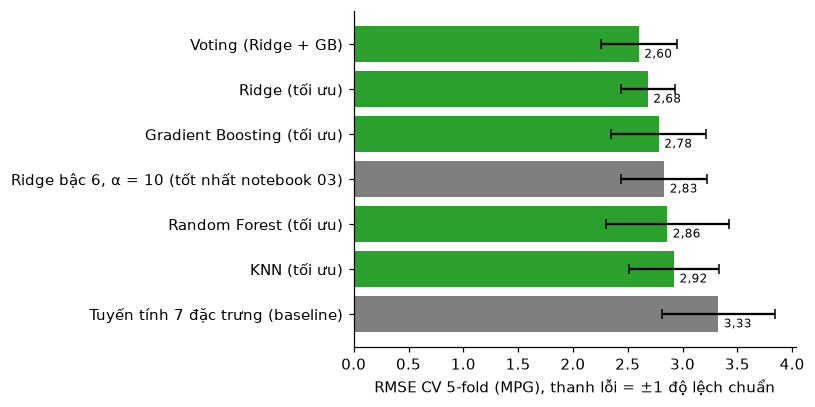

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
s = so_sanh.sort_values("RMSE_cv")
mau = ["C2" if t in ung_vien else "C7" for t in s.index]
ax.barh(s.index, s["RMSE_cv"], xerr=s["RMSE_cv_std"], color=mau, capsize=3)
ax.invert_yaxis(); ax.set_xlabel("RMSE CV 5-fold (MPG), thanh lỗi = ±1 độ lệch chuẩn")
for i, v in enumerate(s["RMSE_cv"]): ax.text(v + 0.05, i + 0.3, f"{v:.2f}".replace(".", ","), fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "hinh_3_10_so_sanh_mo_hinh.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Voting (Ridge + Gradient Boosting) tốt nhất trên 5 fold gốc: RMSE CV 2,601 ± 0,345, MAE 1,87, R² 0,889, giảm 21,8% so với baseline tuyến tính (3,326) và 8,2% so với mô hình tốt nhất notebook 03 (2,833). Voting tốt hơn cả hai thành phần (Ridge 2,683, GB 2,783) vì Ridge cho đường cong trơn toàn cục còn GB học các ngưỡng cục bộ, lỗi của chúng ít tương quan nên trung bình triệt tiêu một phần. Random Forest có RMSE huấn luyện 1,11 nhưng CV 2,861 và độ lệch chuẩn lớn nhất (0,559): vẫn quá khớp dù lấy trung bình nhiều cây. KNN với trọng số theo khoảng cách khớp hoàn hảo tập huấn luyện (RMSE 0) và kém nhất nhóm sau cải tiến (2,923). Thời gian CV đều dưới 3 giây, không phải yếu tố quyết định ở cỡ dữ liệu này.

## 4. Đường cong kiểm định của Gradient Boosting
Lấy từ kết quả GridSearchCV: RMSE theo số cây ở từng tốc độ học, giữ các siêu tham số khác ở giá trị tốt nhất.

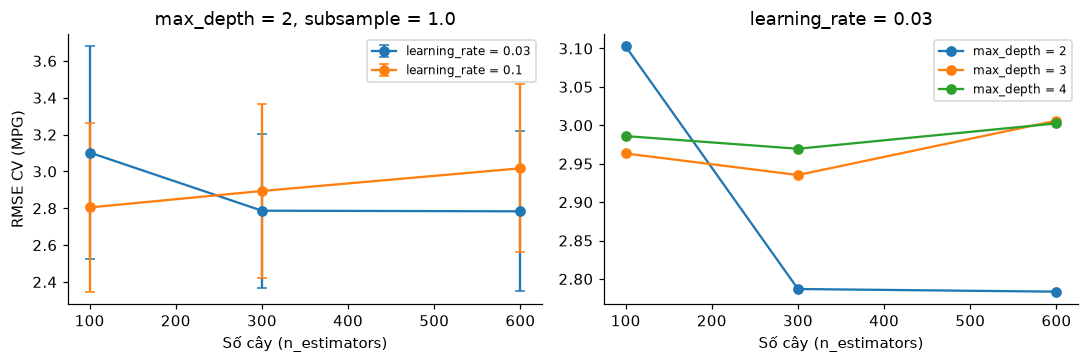

In [6]:
g = luoi["GB"]; cv = pd.DataFrame(g.cv_results_)
bp = {k.split("__")[-1]: v for k, v in g.best_params_.items()}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for lr in [0.03, 0.1]:
    c = cv[(cv["param_regressor__gradientboostingregressor__learning_rate"] == lr) &
           (cv["param_regressor__gradientboostingregressor__max_depth"] == bp["max_depth"]) &
           (cv["param_regressor__gradientboostingregressor__subsample"] == bp["subsample"])]
    ax[0].errorbar(c["param_regressor__gradientboostingregressor__n_estimators"].astype(int), -c["mean_test_score"], yerr=c["std_test_score"],
                   fmt="o-", capsize=3, label=f"learning_rate = {lr}")
ax[0].set_xlabel("Số cây (n_estimators)"); ax[0].set_ylabel("RMSE CV (MPG)"); ax[0].legend(fontsize=8)
ax[0].set_title(f"max_depth = {bp['max_depth']}, subsample = {bp['subsample']}")
for d in [2, 3, 4]:
    c = cv[(cv["param_regressor__gradientboostingregressor__max_depth"] == d) &
           (cv["param_regressor__gradientboostingregressor__learning_rate"] == bp["learning_rate"]) &
           (cv["param_regressor__gradientboostingregressor__subsample"] == bp["subsample"])]
    ax[1].plot(c["param_regressor__gradientboostingregressor__n_estimators"].astype(int), -c["mean_test_score"], "o-", label=f"max_depth = {d}")
ax[1].set_xlabel("Số cây (n_estimators)"); ax[1].legend(fontsize=8); ax[1].set_title(f"learning_rate = {bp['learning_rate']}")
plt.tight_layout(); plt.savefig(FIG / "hinh_3_9_duong_cong_kiem_dinh_gb.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Với learning_rate = 0,1, RMSE CV tốt nhất ở 100 cây (2,81) rồi tăng lên 2,89 và 3,02 khi thêm cây: quá nhiều vòng boosting dẫn tới overfitting. Với learning_rate = 0,03, 100 cây là chưa đủ (3,10, underfitting), cần 300–600 cây (2,79–2,78). Cây nông `max_depth = 2` tốt hơn rõ độ sâu 3–4 (2,94–3,00): với 254 mẫu mỗi fold, tương tác bậc thấp là đủ, cây sâu hơn dễ khớp nhiễu. Độ lệch chuẩn qua fold khoảng 0,4 nên các chênh lệch dưới 0,1 chưa đủ tin cậy.

## 5. Độ ổn định theo seed chia fold và chọn mô hình cuối
Lặp lại CV 5-fold với 5 seed chia fold khác nhau (25 lần đánh giá) cho các ứng viên mạnh nhất, cùng siêu tham số đã chọn ở trên.

In [7]:
on_dinh = {}
for ten in ["Ridge (tối ưu)", "Random Forest (tối ưu)", "Gradient Boosting (tối ưu)", "Voting (Ridge + GB)"]:
    v = []
    for seed in range(5):
        f = cv_folds(train, seed)
        v.append(cv_score(ung_vien[ten], train, y, f)["RMSE_cv"])
    on_dinh[ten] = {"RMSE TB qua 5 seed": np.mean(v), "Độ lệch chuẩn giữa seed": np.std(v), "Nhỏ nhất": np.min(v), "Lớn nhất": np.max(v)}
on_dinh = pd.DataFrame(on_dinh).T
on_dinh.to_csv(REP / "bang_on_dinh_seed.csv")
on_dinh.round(3)

,RMSE TB qua 5 seed,Độ lệch chuẩn giữa seed,Nhỏ nhất,Lớn nhất
Ridge (tối ưu),2.890,0.050,2.832,2.962
Random Forest (tối ưu),2.846,0.037,2.798,2.905
Gradient Boosting (tối ưu),2.811,0.032,2.762,2.853
Voting (Ridge + GB),2.685,0.078,2.547,2.781


**Nhận xét.** Ridge tối ưu đạt 2,683 trên các fold đã dùng để chọn siêu tham số nhưng trung bình 2,890 trên 5 cách chia khác (lạc quan khoảng 0,21). GridSearchCV chọn bậc 3 với α = 0,003, gần như không điều chuẩn, một cấu hình kém ổn định (bậc 3 không điều chuẩn có độ lệch chuẩn qua fold 1,86 ở notebook 03) mà tình cờ hợp với bộ fold gốc: đây là **sai lệch do chọn mô hình** (selection bias). Random Forest và Gradient Boosting gần như không đổi giữa các seed nên đáng tin hơn. Voting vẫn tốt nhất ở trung bình (2,685), và ngay ở seed tệ nhất (2,781) vẫn ngang trung bình của Gradient Boosting (2,811).

**Chọn mô hình cuối: Voting (Ridge + Gradient Boosting)**, theo bốn tiêu chí đánh đổi:
- Độ chính xác: RMSE thấp nhất cả trên 5 fold gốc lẫn trung bình qua 5 seed.
- Độ ổn định: độ lệch chuẩn qua fold 0,345, nhỏ hơn baseline (0,516); dao động giữa các seed (0,078) lớn hơn GB do thành phần Ridge kém ổn định.
- Thời gian: huấn luyện và dự đoán chỉ vài giây.
- Khả năng diễn giải: kém hơn Ridge đơn lẻ, giải thích được bằng permutation importance. Nếu cần mô hình đơn giản hơn, Gradient Boosting (2,811, ổn định nhất) hoặc Ridge bậc 6 (2,833) là lựa chọn thay thế.

In [8]:
TEN_CUOI = "Voting (Ridge + GB)"
cuoi = ung_vien[TEN_CUOI]
print("Mô hình cuối:", TEN_CUOI)

Mô hình cuối: Voting (Ridge + GB)


## 6. Đánh giá một lần trên tập kiểm tra (80 mẫu)
Mô hình cuối được khớp lại trên **toàn bộ 318 mẫu huấn luyện** rồi dự đoán tập kiểm tra. Baseline tuyến tính được đánh giá cùng lúc chỉ để tham chiếu, không dùng để chọn mô hình.

In [9]:
def danh_gia(m):
    p = clone(m).fit(train, y).predict(test)
    return p, {"RMSE": rmse(test[TARGET], p), "MAE": mean_absolute_error(test[TARGET], p), "R2": r2_score(test[TARGET], p)}

p_cuoi, kq_cuoi = danh_gia(cuoi)
p_base, kq_base = danh_gia(tham_chieu["Tuyến tính 7 đặc trưng (baseline)"])
cv_cuoi, cv_base = so_sanh.loc[TEN_CUOI], so_sanh.loc["Tuyến tính 7 đặc trưng (baseline)"]
ket_qua_cuoi = pd.DataFrame({
    "RMSE CV (huấn luyện)": [cv_cuoi.RMSE_cv, cv_base.RMSE_cv], "RMSE kiểm tra": [kq_cuoi["RMSE"], kq_base["RMSE"]],
    "MAE CV": [cv_cuoi.MAE_cv, cv_base.MAE_cv], "MAE kiểm tra": [kq_cuoi["MAE"], kq_base["MAE"]],
    "R² CV": [cv_cuoi.R2_cv, cv_base.R2_cv], "R² kiểm tra": [kq_cuoi["R2"], kq_base["R2"]],
}, index=[TEN_CUOI, "Tuyến tính 7 đặc trưng (baseline)"])
ket_qua_cuoi["Chênh lệch RMSE kiểm tra so với CV (%)"] = (ket_qua_cuoi["RMSE kiểm tra"] / ket_qua_cuoi["RMSE CV (huấn luyện)"] - 1) * 100
ket_qua_cuoi.to_csv(REP / "bang_ket_qua_cuoi.csv")
ket_qua_cuoi.round(3)

,RMSE CV (huấn luyện),RMSE kiểm tra,MAE CV,MAE kiểm tra,R² CV,R² kiểm tra,Chênh lệch RMSE kiểm tra so với CV (%)
Voting (Ridge + GB),2.601,2.314,1.867,1.797,0.889,0.908,-11.028
Tuyến tính 7 đặc trưng (baseline),3.326,3.369,2.579,2.717,0.818,0.806,1.278


In [10]:
# Khoảng tin cậy bootstrap 95% cho RMSE kiểm tra: tập kiểm tra chỉ 80 mẫu nên một con số đơn lẻ dao động khá nhiều
rng = np.random.default_rng(SEED); yt = test[TARGET].to_numpy()
bs = [rmse(yt[i], p_cuoi[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(2000))]
print("RMSE kiểm tra, khoảng tin cậy bootstrap 95%:", np.percentile(bs, [2.5, 97.5]).round(2))
sai = test.assign(du_doan=p_cuoi, loi=yt - p_cuoi).reindex((yt - p_cuoi).__abs__().argsort()[::-1])
print("5 mẫu kiểm tra sai nhiều nhất:"); print(sai[["name", "model_year", "weight", "mpg", "du_doan", "loi"]].head(5).round(1).to_string())

RMSE kiểm tra, khoảng tin cậy bootstrap 95%: [1.86 2.83]
5 mẫu kiểm tra sai nhiều nhất:
                   name  model_year  weight   mpg  du_doan  loi
69  honda civic 1500 gl          80    1850  44.6     35.4  9.2
68           datsun 210          80    2110  40.8     36.2  4.6
22           ford pinto          73    2310  19.0     23.3 -4.3
28    volkswagen dasher          74    1963  26.0     30.3 -4.3
25     oldsmobile omega          73    3664  11.0     15.0 -4.0


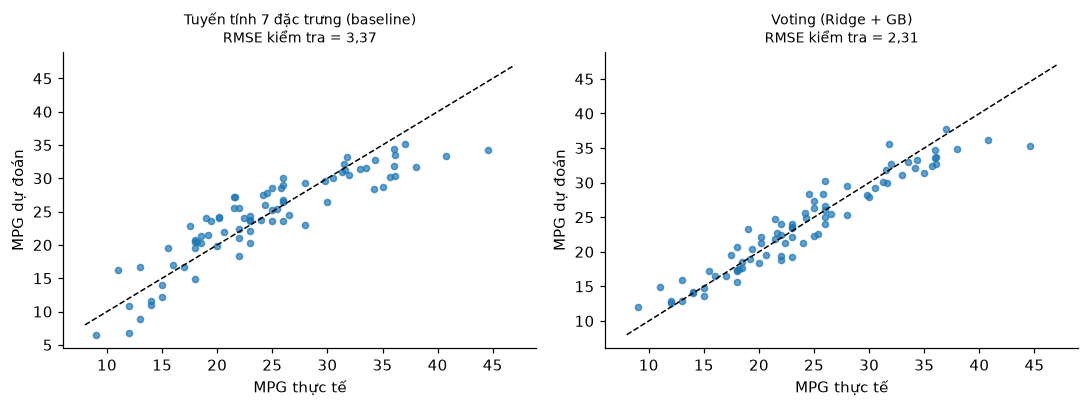

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, p, ten in [(ax[0], p_base, "Tuyến tính 7 đặc trưng (baseline)"), (ax[1], p_cuoi, TEN_CUOI)]:
    a.scatter(test[TARGET], p, s=16, alpha=.7); a.plot([8, 47], [8, 47], "k--", lw=1)
    a.set_title(f"{ten}\nRMSE kiểm tra = {rmse(test[TARGET], p):.2f}".replace(".", ","), fontsize=9)
    a.set_xlabel("MPG thực tế"); a.set_ylabel("MPG dự đoán")
plt.tight_layout(); plt.savefig(FIG / "hinh_3_11_kiem_tra_cuoi.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Trên tập kiểm tra, mô hình cuối đạt RMSE 2,31, MAE 1,80, R² 0,91, giảm 31% RMSE so với baseline tuyến tính (3,37). Chênh lệch RMSE kiểm tra so với CV là −11,0%, nằm trong ngưỡng 15% đặt ở Bảng 5. Khoảng tin cậy bootstrap 95% của RMSE kiểm tra là [1,86; 2,83], chứa giá trị CV (2,60), nên chênh lệch là dao động ngẫu nhiên của 80 mẫu, không phải dấu hiệu rò rỉ; tập kiểm tra cũng có MPG trung bình cao hơn tập huấn luyện (mục 2.3.4). Baseline tuyến tính có RMSE kiểm tra 3,37 so với CV 3,33 (1,3%), cho thấy CV phản ánh đúng khả năng tổng quát hóa. Mẫu sai nhiều nhất là honda civic 1500 gl (đời 1980, 1850 lb): thực tế 44,6 MPG, dự đoán 35,4, đúng nhóm xe nhẹ đời 1980 đã nhận diện ở notebook 04.